# Olist reviews: fine-tuning BERTimbau

Part 3. Fine-tunes [`neuralmind/bert-base-portuguese-cased`](https://huggingface.co/neuralmind/bert-base-portuguese-cased)
on the same split as the baseline and compares quality against cost.

- **Protocol:** best epoch chosen on validation macro-F1 with early stopping; test scored once.
- **Imbalance:** class-weighted cross-entropy (same weighting as the baseline's `class_weight="balanced"`).
- **Outputs:** `bertimbau_metrics.json` (same keys as `baseline_metrics.json`, plus GPU numbers), `comparison.csv`,
  a confusion matrix and the model folder, ready for the Hugging Face Hub.

**Requirements:** GPU (T4), Internet on, notebook 1 as input. Notebook 2 as input is optional (for the comparison table).

## Setup

A single GPU is used (`CUDA_VISIBLE_DEVICES="0"`) so timings are not affected by multi-GPU data parallelism.

In [1]:
import os

os.environ["CUDA_VISIBLE_DEVICES"] = "0"   # use a single GPU (must come before importing torch)
os.environ["WANDB_DISABLED"] = "true"

import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import transformers
from datasets import Dataset
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    f1_score,
)
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    DataCollatorWithPadding,
    EarlyStoppingCallback,
    Trainer,
    TrainingArguments,
    set_seed,
)

SEED = 42
LABELS = ["negative", "neutral", "positive"]  # same order as label_id in notebook 1
ID2LABEL = dict(enumerate(LABELS))            # {0: "negative", 1: "neutral", 2: "positive"}
LABEL2ID = {label: i for i, label in ID2LABEL.items()}

MODEL_NAME = "neuralmind/bert-base-portuguese-cased"

# Hyperparameters
MAX_LENGTH = 128
BATCH_SIZE = 32
LEARNING_RATE = 2e-5
MAX_EPOCHS = 4
USE_CLASS_WEIGHTS = True   # same idea as class_weight="balanced" in the baseline

OUTPUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
MODEL_DIR = OUTPUT_DIR / "bertimbau-olist-sentiment"   # final model, kept as notebook output
CHECKPOINT_DIR = Path("/tmp/checkpoints")               # temporary per-epoch saves, not kept

set_seed(SEED)
print("transformers", transformers.__version__, "| torch", torch.__version__)

transformers 5.20.2 | torch 2.11.0+cu130


In [2]:
if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU found. In the right-hand panel: Settings -> Accelerator -> GPU T4 x2. "
        "If the option is greyed out, verify your phone number on your Kaggle account first."
    )

DEVICE = torch.device("cuda")
GPU_NAME = torch.cuda.get_device_name(0)
print("GPU:", GPU_NAME)

GPU: Tesla T4


## Load the split

In [3]:
INPUT_DIR = Path("/kaggle/input") if Path("/kaggle/input").exists() else Path(".")
validation_file = next(INPUT_DIR.rglob("validation.csv"), None)

if validation_file is None:
    raise FileNotFoundError(
        "validation.csv not found. Add notebook 1 with 'Add Input -> Your Work' in the right-hand panel."
    )

DATA_DIR = validation_file.parent
print("Reading from:", DATA_DIR)

train = pd.read_csv(DATA_DIR / "train.csv", keep_default_na=False)
validation = pd.read_csv(DATA_DIR / "validation.csv", keep_default_na=False)
test = pd.read_csv(DATA_DIR / "test.csv", keep_default_na=False)

for name, part in {"train": train, "validation": validation, "test": test}.items():
    print(f"{name:>10}: {len(part):>6,} reviews")

Reading from: /kaggle/input/notebooks/patrickjunmiyauraihy/olist-reviews-data-preparation-and-split
     train: 29,175 reviews
validation:  3,647 reviews
      test:  3,647 reviews


## Tokenization

Token-length statistics check that `max_length=128` truncates almost nothing.
Padding is dynamic (per batch) via `DataCollatorWithPadding`.

In [4]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

example = train["text"].iloc[0]
print(example)
print(tokenizer.tokenize(example))

lengths = [len(ids) for ids in tokenizer(train["text"].tolist())["input_ids"]]
lengths = pd.Series(lengths)
print()
print(lengths.describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))
print(f"Reviews longer than {MAX_LENGTH} tokens: {(lengths > MAX_LENGTH).mean():.1%}")

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

Recomendo a todos podem compra sem medo garantido por mim
['Rec', '##ome', '##ndo', 'a', 'todos', 'podem', 'compra', 'sem', 'medo', 'garant', '##ido', 'por', 'mim']

count    29175.0
mean        22.2
std         15.0
min          3.0
50%         18.0
90%         45.0
95%         51.0
99%         64.0
max        205.0
dtype: float64
Reviews longer than 128 tokens: 0.0%


In [5]:
def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LENGTH)


def to_dataset(df: pd.DataFrame) -> Dataset:
    ds = Dataset.from_pandas(df[["text", "label_id"]].rename(columns={"label_id": "labels"}), preserve_index=False)
    return ds.map(tokenize, batched=True, remove_columns=["text"])


train_ds = to_dataset(train)
val_ds = to_dataset(validation)
test_ds = to_dataset(test)

collator = DataCollatorWithPadding(tokenizer=tokenizer)
print(train_ds)

Map:   0%|          | 0/29175 [00:00<?, ? examples/s]

Map:   0%|          | 0/3647 [00:00<?, ? examples/s]

Map:   0%|          | 0/3647 [00:00<?, ? examples/s]

Dataset({
    features: ['labels', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 29175
})


## Model

A new 3-way classification head is added on top of the pre-trained encoder. The load report lists the head as
missing (newly initialized) and the pre-training heads as unused; both are expected.

In [6]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(LABELS),
    id2label=ID2LABEL,
    label2id=LABEL2ID,
)
n_params = sum(p.numel() for p in model.parameters())
print(f"Parameters: {n_params / 1e6:.0f} million")

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from th

Parameters: 109 million


### Class weights

`n / (n_classes × n_c)`, applied through a `Trainer` subclass that overrides `compute_loss`.

In [7]:
counts = train["label_id"].value_counts().sort_index().to_numpy()
class_weights = torch.tensor(len(train) / (len(LABELS) * counts), dtype=torch.float)
print(dict(zip(LABELS, class_weights.numpy().round(2))))


class WeightedTrainer(Trainer):
    """A Trainer whose loss gives rare classes more weight."""

    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs["labels"]
        outputs = model(**{k: v for k, v in inputs.items() if k != "labels"})
        weight = self.class_weights.to(outputs.logits.device) if self.class_weights is not None else None
        loss = torch.nn.functional.cross_entropy(outputs.logits.float(), labels, weight=weight)
        return (loss, outputs) if return_outputs else loss

model.safetensors: downloading bytes:           |  0.00B            

{'negative': np.float32(1.17), 'neutral': np.float32(3.72), 'positive': np.float32(0.53)}


## Training configuration

Learning rate 2e-5, batch size 32, up to 4 epochs, linear schedule with 10% warmup, weight decay 0.01, fp16.
Validation is scored each epoch; the best checkpoint by macro-F1 is restored at the end, and training stops
after one epoch without improvement.

In [8]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "macro_f1": f1_score(labels, preds, average="macro"),
        "neutral_f1": f1_score(labels, preds, labels=[LABEL2ID["neutral"]], average="macro"),
        "accuracy": accuracy_score(labels, preds),
    }


steps_per_epoch = int(np.ceil(len(train_ds) / BATCH_SIZE))
warmup_steps = int(0.1 * steps_per_epoch * MAX_EPOCHS)

args = TrainingArguments(
    output_dir=str(CHECKPOINT_DIR),
    num_train_epochs=MAX_EPOCHS,
    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE * 2,
    learning_rate=LEARNING_RATE,
    weight_decay=0.01,
    warmup_steps=warmup_steps,
    lr_scheduler_type="linear",
    fp16=True,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    greater_is_better=True,
    logging_steps=100,
    report_to="none",
    seed=SEED,
)

trainer = WeightedTrainer(
    model=model,
    args=args,
    train_dataset=train_ds,
    eval_dataset=val_ds,
    data_collator=collator,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=1)],
    class_weights=class_weights if USE_CLASS_WEIGHTS else None,
)
print(f"{steps_per_epoch} steps per epoch, {warmup_steps} warmup steps")

912 steps per epoch, 364 warmup steps


## Training

In [9]:
torch.cuda.synchronize()
start = time.perf_counter()
train_result = trainer.train()
torch.cuda.synchronize()
train_seconds = time.perf_counter() - start

print(f"Training time (GPU): {train_seconds / 60:.1f} min")
print(f"Best validation macro-F1: {trainer.state.best_metric:.4f}")
print(f"Best checkpoint: {trainer.state.best_model_checkpoint}")

Epoch,Training Loss,Validation Loss,Macro F1,Neutral F1,Accuracy
1,0.612144,0.613687,0.694562,0.355086,0.803400
2,0.574594,0.613346,0.701468,0.355221,0.821771
3,0.418846,0.776401,0.698108,0.327698,0.837126


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training time (GPU): 5.2 min
Best validation macro-F1: 0.7015
Best checkpoint: /tmp/checkpoints/checkpoint-1824


In [10]:
history = pd.DataFrame([row for row in trainer.state.log_history if "eval_macro_f1" in row])
history = history[["epoch", "eval_loss", "eval_macro_f1", "eval_neutral_f1", "eval_accuracy"]].round(4)
best_epoch = float(history.loc[history["eval_macro_f1"].idxmax(), "epoch"])
print(f"Best epoch: {best_epoch:g}")
history

Best epoch: 2


,epoch,eval_loss,eval_macro_f1,eval_neutral_f1,eval_accuracy
0,1.0,0.6137,0.6946,0.3551,0.8034
1,2.0,0.6133,0.7015,0.3552,0.8218
2,3.0,0.7764,0.6981,0.3277,0.8371


## Test evaluation

In [11]:
torch.cuda.synchronize()
start = time.perf_counter()
test_output = trainer.predict(test_ds)
torch.cuda.synchronize()
test_gpu_seconds = time.perf_counter() - start

test_pred = [ID2LABEL[i] for i in np.argmax(test_output.predictions, axis=-1)]
y_test = test["label"]

test_macro_f1 = f1_score(y_test, test_pred, average="macro")
test_accuracy = accuracy_score(y_test, test_pred)

print(f"Test macro-F1: {test_macro_f1:.3f}   (baseline: 0.661)")
print(f"Test accuracy: {test_accuracy:.3f}   (baseline: 0.790)")
print()
print(classification_report(y_test, test_pred, labels=LABELS, digits=3))

Test macro-F1: 0.689   (baseline: 0.661)
Test accuracy: 0.809   (baseline: 0.790)

              precision    recall  f1-score   support

    negative      0.848     0.797     0.822      1043
     neutral      0.254     0.495     0.336       327
    positive      0.965     0.859     0.909      2277

    accuracy                          0.809      3647
   macro avg      0.689     0.717     0.689      3647
weighted avg      0.867     0.809     0.833      3647



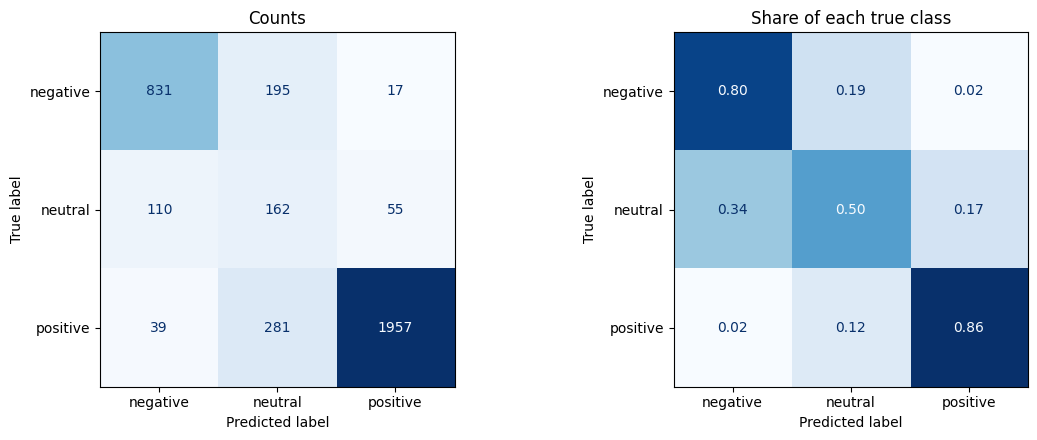

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, normalize, title in [(axes[0], None, "Counts"), (axes[1], "true", "Share of each true class")]:
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_pred, labels=LABELS, normalize=normalize,
        values_format=".2f" if normalize else "d", cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(title)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "bertimbau_confusion_matrix.png", dpi=150)
plt.show()

## Error analysis

In [13]:
errors = test.assign(predicted=test_pred).query("label != predicted")
print(f"{len(errors):,} errors out of {len(test):,} test reviews\n")

for label in LABELS:
    sample = errors[errors["label"] == label].sample(
        min(4, (errors["label"] == label).sum()), random_state=SEED
    )
    for row in sample.itertuples():
        print(f"[true={row.label} | predicted={row.predicted} | {row.review_score} stars] {row.text[:160]}")
    print()

697 errors out of 3,647 test reviews

[true=negative | predicted=neutral | 2 stars] A garrafa foi entregue , só falta o fone bluetooth
[true=negative | predicted=neutral | 2 stars] O produto chegou antes do prazo, mas a qualidade das fronhas e' muito ruim. Uma delas ja desfiou.
[true=negative | predicted=neutral | 2 stars] Gostei do produto chegou antes do prazo, mas fiquei triste pq eu tinha feito um pedido antes e foi cancelado recebo um email que tinha sido cancelado por diverg
[true=negative | predicted=positive | 1 stars] Cumpriu com excelência

[true=neutral | predicted=negative | 3 stars] Comprei outros produtos na loja e chegaram e um deles não chegou. Estou aguardando.
[true=neutral | predicted=positive | 3 stars] O produto foi entregue antes do prazo! Parabéns!
[true=neutral | predicted=negative | 3 stars] nao ecebi prodoutos
[true=neutral | predicted=positive | 3 stars] Manete. Recomendo

[true=positive | predicted=negative | 5 stars] Comprei dois rolos de cabo 10 mm, um ver

## Save the model

Weights, config (with `id2label`) and tokenizer, in the layout the Hugging Face Hub expects.

In [14]:
trainer.save_model(str(MODEL_DIR))
tokenizer.save_pretrained(str(MODEL_DIR))

weight_files = list(MODEL_DIR.glob("*.safetensors")) + list(MODEL_DIR.glob("*.bin"))
model_mb = sum(f.stat().st_size for f in weight_files) / 1e6

for f in sorted(MODEL_DIR.iterdir()):
    print(f"{f.name:<28} {f.stat().st_size / 1e6:8.1f} MB")
print(f"\nModel weights: {model_mb:.0f} MB")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

config.json                       0.0 MB
model.safetensors               435.7 MB
tokenizer.json                    0.7 MB
tokenizer_config.json             0.0 MB
training_args.bin                 0.0 MB

Model weights: 436 MB


## Cost and latency

Single-review latency (median, after warm-up) on GPU and CPU, GPU throughput on the full test set, and
CPU throughput on 512 reviews. CPU numbers are the like-for-like comparison with the baseline;
training time is not, since the baseline trained on a CPU.

In [15]:
def predict_one(model, text, device):
    inputs = tokenizer(text, truncation=True, max_length=MAX_LENGTH, return_tensors="pt").to(device)
    with torch.inference_mode():
        return model(**inputs).logits.argmax(-1).item()


def median_latency_ms(model, text, device, runs):
    for _ in range(5):  # warm-up
        predict_one(model, text, device)
    timings = []
    for _ in range(runs):
        if device.type == "cuda":
            torch.cuda.synchronize()
        start = time.perf_counter()
        predict_one(model, text, device)
        if device.type == "cuda":
            torch.cuda.synchronize()
        timings.append(time.perf_counter() - start)
    return float(np.median(timings) * 1000)


best_model = trainer.model.eval()
sample_text = test["text"].iloc[0]

latency_gpu_ms = median_latency_ms(best_model.to(DEVICE), sample_text, DEVICE, runs=100)
throughput_gpu = len(test) / test_gpu_seconds

cpu = torch.device("cpu")
best_model = best_model.to(cpu)
latency_cpu_ms = median_latency_ms(best_model, sample_text, cpu, runs=50)

# CPU throughput on a 512-review subset
cpu_texts = test["text"].iloc[:512].tolist()
start = time.perf_counter()
for i in range(0, len(cpu_texts), BATCH_SIZE):
    batch = tokenizer(cpu_texts[i:i + BATCH_SIZE], truncation=True, max_length=MAX_LENGTH,
                      padding=True, return_tensors="pt")
    with torch.inference_mode():
        best_model(**batch)
throughput_cpu = len(cpu_texts) / (time.perf_counter() - start)

print(f"Training time (GPU {GPU_NAME}): {train_seconds / 60:.1f} min")
print(f"Latency, one review, GPU (median): {latency_gpu_ms:.1f} ms")
print(f"Latency, one review, CPU (median): {latency_cpu_ms:.1f} ms")
print(f"Throughput GPU (test set):   {throughput_gpu:,.0f} reviews/s")
print(f"Throughput CPU (512 reviews): {throughput_cpu:,.0f} reviews/s")
print(f"Model weights: {model_mb:.0f} MB")

Training time (GPU Tesla T4): 5.2 min
Latency, one review, GPU (median): 10.1 ms
Latency, one review, CPU (median): 58.9 ms
Throughput GPU (test set):   868 reviews/s
Throughput CPU (512 reviews): 17 reviews/s
Model weights: 436 MB


## Metrics and comparison with the baseline

In [16]:
report = classification_report(y_test, test_pred, labels=LABELS, output_dict=True)
majority_pred = ["positive"] * len(validation)

metrics = {
    "model": "bertimbau_finetuned",
    "best_params": {
        "base_model": MODEL_NAME,
        "max_length": MAX_LENGTH,
        "batch_size": BATCH_SIZE,
        "learning_rate": LEARNING_RATE,
        "max_epochs": MAX_EPOCHS,
        "best_epoch": best_epoch,
        "class_weights": USE_CLASS_WEIGHTS,
    },
    "validation_macro_f1": round(float(trainer.state.best_metric), 4),
    "test_macro_f1": round(float(test_macro_f1), 4),
    "test_accuracy": round(float(test_accuracy), 4),
    "test_per_class": {
        label: {m: round(float(report[label][m]), 4) for m in ["precision", "recall", "f1-score"]}
        for label in LABELS
    },
    "majority_class_val_macro_f1": round(float(f1_score(validation["label"], majority_pred, average="macro")), 4),
    "train_seconds_gpu": round(train_seconds, 1),
    "gpu": GPU_NAME,
    "latency_ms_single_cpu": round(latency_cpu_ms, 3),
    "latency_ms_single_gpu": round(latency_gpu_ms, 3),
    "throughput_reviews_per_s_cpu": round(throughput_cpu),
    "throughput_reviews_per_s_gpu": round(throughput_gpu),
    "model_size_mb": round(model_mb, 2),
    "n_train": len(train),
    "n_test": len(test),
}

with open(OUTPUT_DIR / "bertimbau_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print(json.dumps(metrics, indent=2))

{
  "model": "bertimbau_finetuned",
  "best_params": {
    "base_model": "neuralmind/bert-base-portuguese-cased",
    "max_length": 128,
    "batch_size": 32,
    "learning_rate": 2e-05,
    "max_epochs": 4,
    "best_epoch": 2.0,
    "class_weights": true
  },
  "validation_macro_f1": 0.7015,
  "test_macro_f1": 0.6888,
  "test_accuracy": 0.8089,
  "test_per_class": {
    "negative": {
      "precision": 0.848,
      "recall": 0.7967,
      "f1-score": 0.8216
    },
    "neutral": {
      "precision": 0.2539,
      "recall": 0.4954,
      "f1-score": 0.3358
    },
    "positive": {
      "precision": 0.9645,
      "recall": 0.8595,
      "f1-score": 0.909
    }
  },
  "majority_class_val_macro_f1": 0.2563,
  "train_seconds_gpu": 312.3,
  "gpu": "Tesla T4",
  "latency_ms_single_cpu": 58.851,
  "latency_ms_single_gpu": 10.117,
  "throughput_reviews_per_s_cpu": 17,
  "throughput_reviews_per_s_gpu": 868,
  "model_size_mb": 435.73,
  "n_train": 29175,
  "n_test": 3647
}


In [17]:
baseline_file = next(INPUT_DIR.rglob("baseline_metrics.json"), None)
if baseline_file is not None:
    baseline = json.loads(baseline_file.read_text())
    print("Baseline read from:", baseline_file)
else:
    print("baseline_metrics.json not attached; using the numbers from notebook 2's last run.")
    baseline = {
        "model": "tfidf_logreg", "test_macro_f1": 0.6606, "test_accuracy": 0.7902,
        "test_per_class": {"negative": {"f1-score": 0.7899}, "neutral": {"f1-score": 0.3007},
                           "positive": {"f1-score": 0.8911}},
        "train_seconds_cpu": 6.19, "latency_ms_single_cpu": 1.067,
        "throughput_reviews_per_s_cpu": 42732, "model_size_mb": 1.61,
    }


def row(m):
    per_class = m["test_per_class"]
    return {
        "test macro-F1": m["test_macro_f1"],
        "test accuracy": m["test_accuracy"],
        "F1 negative": per_class["negative"]["f1-score"],
        "F1 neutral": per_class["neutral"]["f1-score"],
        "F1 positive": per_class["positive"]["f1-score"],
        "train time (s)": m.get("train_seconds_cpu") or m.get("train_seconds_gpu"),
        "trained on": "CPU" if "train_seconds_cpu" in m else "GPU",
        "latency 1 review, CPU (ms)": m.get("latency_ms_single_cpu"),
        "latency 1 review, GPU (ms)": m.get("latency_ms_single_gpu"),
        "throughput CPU (reviews/s)": m.get("throughput_reviews_per_s_cpu"),
        "model size (MB)": m.get("model_size_mb"),
    }


comparison = pd.DataFrame({"TF-IDF + LogReg": row(baseline), "BERTimbau": row(metrics)})
comparison.to_csv(OUTPUT_DIR / "comparison.csv")

gain = metrics["test_macro_f1"] - baseline["test_macro_f1"]
slower = metrics["latency_ms_single_cpu"] / baseline["latency_ms_single_cpu"]
bigger = metrics["model_size_mb"] / baseline["model_size_mb"]
print(f"\nBERTimbau: {gain:+.3f} macro-F1, {slower:,.0f}x slower per review on CPU, {bigger:,.0f}x bigger.")
comparison

Baseline read from: /kaggle/input/notebooks/patrickjunmiyauraihy/olist-reviews-tf-idf-logistic-regression-bl/baseline_metrics.json

BERTimbau: +0.028 macro-F1, 52x slower per review on CPU, 271x bigger.


,TF-IDF + LogReg,BERTimbau
test macro-F1,0.6606,0.6888
test accuracy,0.7902,0.8089
F1 negative,0.7899,0.8216
F1 neutral,0.3007,0.3358
F1 positive,0.8911,0.909
train time (s),6.63,312.3
trained on,CPU,GPU
"latency 1 review, CPU (ms)",1.141,58.851
"latency 1 review, GPU (ms)",None,10.117
throughput CPU (reviews/s),39158,17


## Publish to the Hugging Face Hub (optional)

Requires a write token stored as the Kaggle secret `HF_TOKEN`. Set `HF_REPO` and `PUSH_TO_HUB = True`.

In [18]:
PUSH_TO_HUB = True
HF_REPO = "patrickjunmiyauraihy/bertimbau-olist-sentiment"

if PUSH_TO_HUB:
    from huggingface_hub import HfApi
    from kaggle_secrets import UserSecretsClient

    token = UserSecretsClient().get_secret("HF_TOKEN")
    api = HfApi(token=token)
    api.create_repo(HF_REPO, exist_ok=True)
    api.upload_folder(folder_path=str(MODEL_DIR), repo_id=HF_REPO, commit_message="Upload fine-tuned BERTimbau")
    api.upload_file(path_or_fileobj=str(OUTPUT_DIR / "bertimbau_metrics.json"),
                    path_in_repo="bertimbau_metrics.json", repo_id=HF_REPO)
    print(f"Published: https://huggingface.co/{HF_REPO}")
else:
    print("Skipped (PUSH_TO_HUB = False).")

Published: https://huggingface.co/patrickjunmiyauraihy/bertimbau-olist-sentiment


## Data and license

Olist, *Brazilian E-Commerce Public Dataset by Olist*, Kaggle, CC BY-NC-SA 4.0.
BERTimbau: Souza, Nogueira and Lotufo (2020), *BERTimbau: pretrained BERT models for Brazilian Portuguese*, MIT license.